# Module 2 — Differential Gene Expression

**Goal:** Identify genes whose expression level differs significantly between each PAM50 subtype and all other subtypes combined (one-vs-rest).

**Method:**

- **Input data:** UCSC Xena stores STAR counts as log₂(count + 1) — the file is already normalized, so no further transform is applied.
- **Test:** Welch's t-test (does not assume equal variance — appropriate because group sizes differ).
- **Multiple testing:** 5 subtypes × 5 000 genes = 25 000 tests. Benjamini-Hochberg FDR correction applied within each subtype's 5 000 tests.
- **Significance threshold:** FDR < 0.05 **and** |log₂FC| ≥ 1.0 (at least 2× fold change).

A gene with log₂FC > 0 is **upregulated** in the subtype; log₂FC < 0 means **downregulated**.


In [ ]:
import sys
sys.path.insert(0, "..")

import logging
import pandas as pd
import matplotlib.pyplot as plt

from src.constants import InterimFile, KNOWN_MARKERS
from src.paths import interim_file
from src.features.differential_expression import run_one_vs_rest, top_de_genes
from src.visualization.volcano import plot_all_volcanos

logging.basicConfig(level=logging.INFO, format="%(message)s")

## Load Data


In [2]:
X = pd.read_csv(interim_file(InterimFile.X), index_col=0)
labels = pd.read_csv(interim_file(InterimFile.LABELS), index_col=0).squeeze()

print(f"X:      {X.shape[0]:>5} samples x {X.shape[1]:>5} genes")
print(f"labels: {len(labels):>5} samples")
print()
print(labels.value_counts())

X:        842 samples x  5000 genes
labels:   842 samples

PAM50Call_RNAseq
LumA      421
LumB      192
Basal     139
Her2       67
Normal     23
Name: count, dtype: int64


## Run Differential Expression


In [3]:
FDR_THRESHOLD = 0.05
LOG2FC_THRESHOLD = 1.0  # >= 2x fold change

results = run_one_vs_rest(
    X=X,
    labels=labels,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
)
results.head(3)

One-vs-rest DGE: 5 subtypes × 5000 genes = 25000 tests
  Basal     n=139
  Her2      n=67
  LumA      n=421
  LumB      n=192
  Normal    n=23
Significant pairs (FDR<0.05, |log2FC|≥1.0): 7871 / 25000


,gene,subtype,log2fc,pval,padj,mean_subtype,mean_rest,n_subtype,n_rest,significant
0,ENSG00000166509.12,Basal,-4.947040,6.778063e-47,8.049956e-46,2.192265,7.139305,139,703,True
1,ENSG00000110484.7,Basal,-6.277185,8.148238e-40,7.172744e-39,5.805762,12.082947,139,703,True
2,ENSG00000153002.12,Basal,-5.271251,8.501611e-47,1.002548e-45,4.102785,9.374036,139,703,True


## Significant Genes per Subtype

How many gene-subtype pairs pass the threshold, broken down by direction?


In [4]:
sig = results[results["significant"]].copy()
sig["direction"] = sig["log2fc"].apply(lambda x: "up" if x > 0 else "down")

summary = (
    sig.groupby(["subtype", "direction"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["up", "down"])
)
summary["total"] = summary.sum(axis=1)
summary.sort_values("total", ascending=False)

direction,up,down,total
subtype,,,
Basal,1238,1435,2673
Normal,1187,423,1610
Her2,649,760,1409
LumA,899,451,1350
LumB,268,561,829


## Top DE Genes per Subtype

Top 10 upregulated genes per subtype (ranked by adjusted p-value).

> **Note:** Gene IDs are Ensembl IDs with version suffix (e.g. `ENSG00000141736.14`). A future step would map these to HGNC symbols via biomaRt or MyGene.info.


In [5]:
top_up = top_de_genes(results, n=10, direction="up")

display_cols = ["subtype", "gene", "log2fc", "padj", "mean_subtype", "mean_rest"]
(
    top_up[display_cols]
    .style
    .format({"log2fc": "{:.2f}", "padj": "{:.2e}",
             "mean_subtype": "{:.2f}", "mean_rest": "{:.2f}"})
    .background_gradient(subset="log2fc", cmap="Reds")
)

,subtype,gene,log2fc,padj,mean_subtype,mean_rest
0,Basal,ENSG00000119866.22,4.54,8.23e-111,11.05,6.50
1,Basal,ENSG00000280916.2,6.54,4.87e-83,8.98,2.44
2,Basal,ENSG00000054598.9,4.10,1.99e-79,12.44,8.35
3,Basal,ENSG00000213130.3,4.20,1.14e-76,5.72,1.53
4,Basal,ENSG00000144354.14,3.16,7.90e-75,10.76,7.59
5,Basal,ENSG00000135069.14,4.24,4.28e-72,11.54,7.30
6,Basal,ENSG00000288009.1,3.14,1.12e-71,5.66,2.52
7,Basal,ENSG00000176597.12,2.85,2.69e-70,10.52,7.66
8,Basal,ENSG00000065371.17,6.54,1.46e-69,8.84,2.30
9,Basal,ENSG00000281406.2,4.62,2.76e-69,7.97,3.35


## Volcano Plots

Each point is one gene. x-axis = log₂FC (positive = higher in this subtype). y-axis = -log₁₀(FDR-adjusted p-value). Red = significantly up, blue = significantly down, grey = not significant. Dashed lines mark the thresholds.


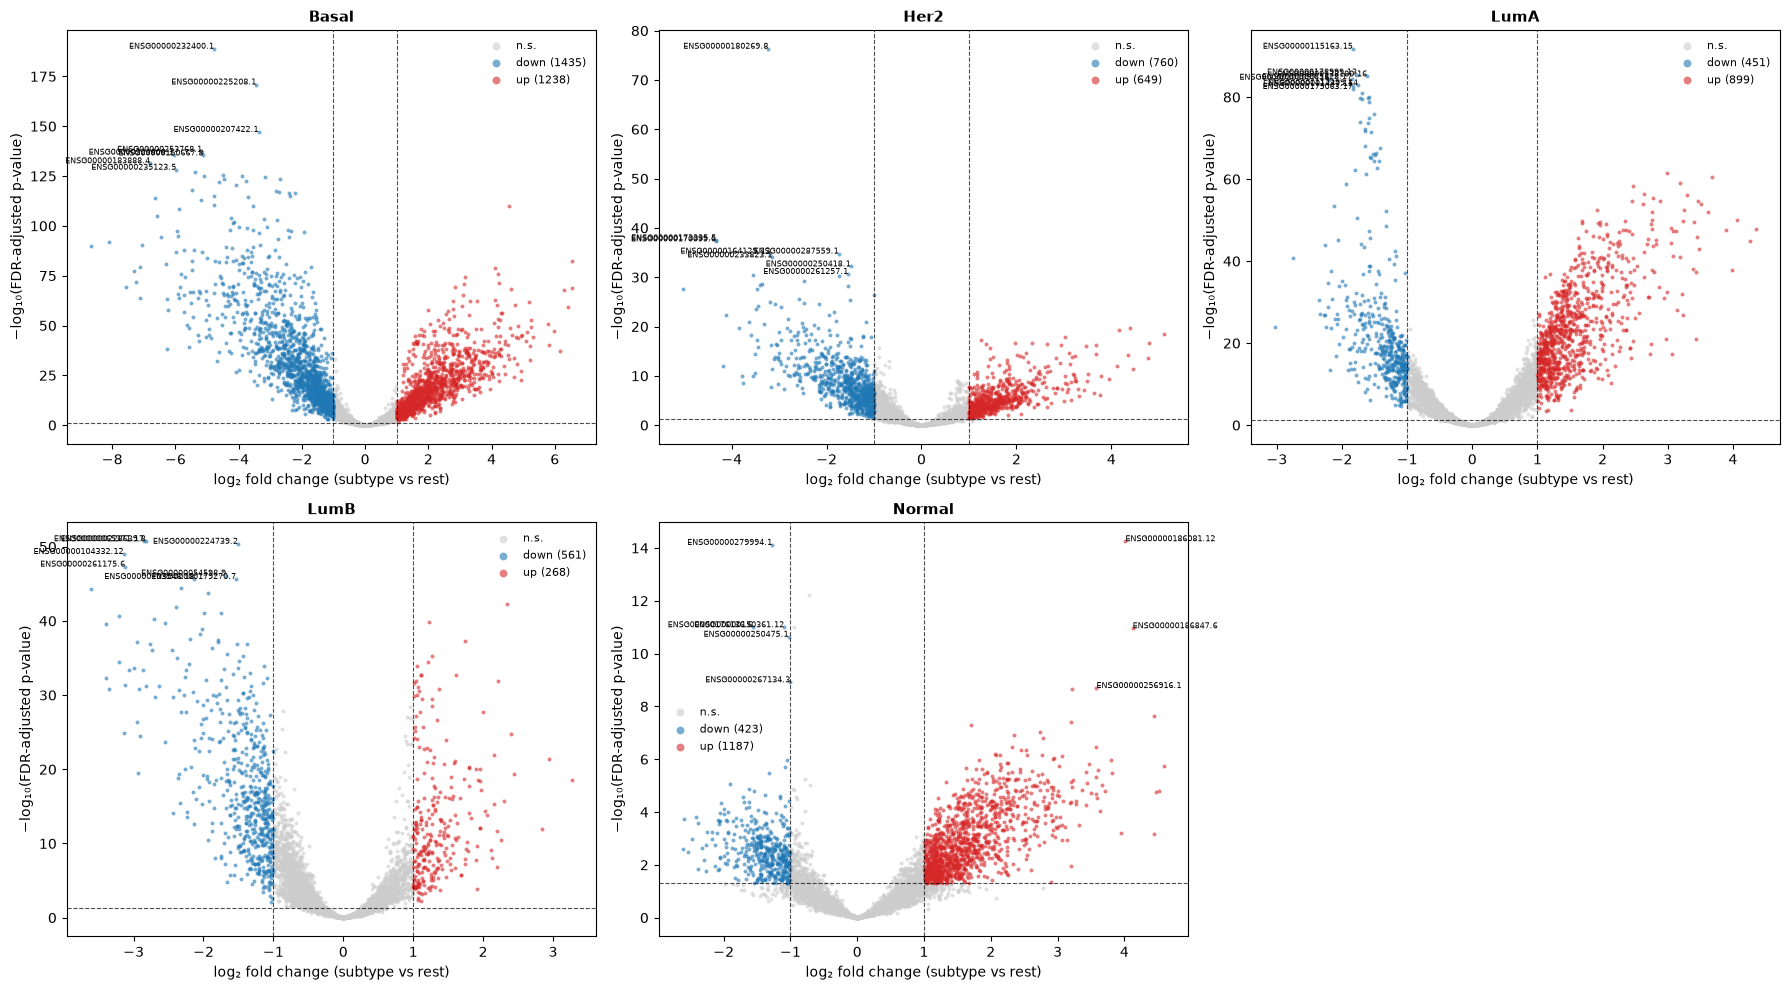

In [6]:
fig = plot_all_volcanos(
    results,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
    n_label=8,
    ncols=3,
)
plt.show()

## Known Marker Validation

A credible DGE result should recover established PAM50 biomarkers. We check whether canonical markers from the literature appear in our significant genes.

Genes are stored as versioned Ensembl IDs (e.g. `ENSG00000141736.14`), so we match on the base ID.


In [7]:
results["gene_base"] = results["gene"].str.split(".").str[0]

rows = []
for subtype, marker_ids in KNOWN_MARKERS.items():
    for ensembl_id in marker_ids:
        hit = results[
            (results["subtype"] == subtype) & (results["gene_base"] == ensembl_id)
        ]
        if hit.empty:
            rows.append({"subtype": subtype, "ensembl_id": ensembl_id,
                         "in_top5000": False, "significant": False,
                         "log2fc": None, "padj": None})
        else:
            r = hit.iloc[0]
            rows.append({"subtype": subtype, "ensembl_id": ensembl_id,
                         "in_top5000": True, "significant": bool(r["significant"]),
                         "log2fc": round(float(r["log2fc"]), 2),
                         "padj": f"{r['padj']:.2e}"})

marker_df = pd.DataFrame(rows)
print(f"Markers in top-5000 variable genes: {marker_df['in_top5000'].sum()} / {len(marker_df)}")
print(f"Markers also significant:           {marker_df['significant'].sum()} / {marker_df['in_top5000'].sum()}")
marker_df

Markers in top-5000 variable genes: 8 / 16
Markers also significant:           7 / 8


,subtype,ensembl_id,in_top5000,significant,log2fc,padj
0,Basal,ENSG00000012048,False,False,NaN,None
1,Basal,ENSG00000186081,True,True,3.04,7.68e-21
2,Basal,ENSG00000143228,True,True,1.51,2.70e-36
3,Basal,ENSG00000166033,False,False,NaN,None
4,HER2,ENSG00000141736,False,False,NaN,None
5,HER2,ENSG00000140443,False,False,NaN,None
6,HER2,ENSG00000132965,False,False,NaN,None
7,LumA,ENSG00000091831,True,True,3.12,3.70e-48
8,LumA,ENSG00000129514,True,True,2.22,1.67e-33
9,LumA,ENSG00000107485,True,True,1.86,1.48e-38


## Save Results


In [8]:
out = interim_file(InterimFile.DE_RESULTS)
results.drop(columns="gene_base", errors="ignore").to_csv(out, index=False)
print(f"Saved {out.name}  ({len(results):,} rows)")

Saved de_results.csv.gz  (25,000 rows)
